# Redes Neuronales 2026 — Trabajo Práctico 1
## Simulación numérica del modelo de neuronas de Izhikevich

Notebook con el código completo del TP, siguiendo la estructura de la guía 6:

1. **Ejercicio 1.** Librerías e integradores (Euler, RK4 e `integrador_ode`).
2. **Ejercicio 2.** Modelo de Izhikevich: caso base (ítems 1 y 2) y los ocho paneles de la figura 2 del paper (ítem 3).
3. **Análisis extra** para la discusión: plano de fase, curva f–I, condición inicial y error numérico.
4. **Ejercicio 3 (opcional).** Red de 1000 neuronas con Euler–Maruyama, activación Θ y z(v) (figura 3 del paper).

Referencia: E. M. Izhikevich, *Simple model of spiking neurons*, IEEE Trans. Neural Netw. 14(6), 1569 (2003).

## Ejercicio 1) Librerías e integradores

In [1]:
# 1.1)
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
# 1.2) Integradores de la guía anterior
def euler(f, x, t, h, p):
    """Un paso del método de Euler: x(t+h) ≈ x + h f(x,t,p)."""
    return x + h*f(x, t, p)

def rk4(f, x, t, h, p):
    """Un paso del método de Runge-Kutta de orden 4."""
    k1 = f(x, t, p)
    k2 = f(x + 0.5*h*k1, t + 0.5*h, p)
    k3 = f(x + 0.5*h*k2, t + 0.5*h, p)
    k4 = f(x + h*k3, t + h, p)
    return x + h*(k1 + 2.0*k2 + 2.0*k3 + k4)/6.0

def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
    """
    Integra dx/dt = f(x,t,p) en [a,b] con k pasos del método m y condición inicial x(a)=xa.
    c(x,t,p) es la función condicionante que se aplica después de cada paso:
    la usamos para implementar el reseteo del disparo.
    Retorna t (k+1) y w (n x k+1) con w[i,j] = x_i(t_j).
    """
    assert k > 0
    n = len(xa)
    h = (b - a)/k
    w = np.zeros((n, k+1))
    t = np.zeros(k+1)
    w[:, 0] = xa
    t[0] = a
    for j in range(k):
        t[j+1] = t[j] + h
        w[:, j+1] = m(f, w[:, j], t[j], h, p)
        w[:, j+1] = c(w[:, j+1], t[j+1], p)
    return t, w

## Ejercicio 2) Modelo de Izhikevich

$$\dot v = g_2 v^2 + g_1 v + g_0 - u + I(t), \qquad \dot u = b\,(c\,v - u)$$

con el reseteo: si $v \ge v^+$ entonces $v \leftarrow v^-$ y $u \leftarrow u + \Delta u$.

El vector de parámetros es `p = (g2, g1, g0, v_menos, v_mas, b, c, du, I)`, donde `I` es **una función de t** (no un número).

In [3]:
def izhikevich(x, t, p):
    """Campo vectorial f(x,t,p) con x = (v, u)."""
    g2, g1, g0, vm, vp, b, c, du, I = p
    v, u = x
    return np.array([g2*v**2 + g1*v + g0 - u + I(t),
                     b*(c*v - u)])

def reseteo(x, t, p):
    """Función condicionante: si v >= v+, v <- v- y u <- u + du."""
    g2, g1, g0, vm, vp, b, c, du, I = p
    if x[0] >= vp:
        return np.array([vm, x[1] + du])
    return x

def parametros(b=0.02, c=0.2, v_menos=-65.0, du=2.0, I=None,
               g2=0.04, g1=5.0, g0=140.0, v_mas=30.0):
    return (g2, g1, g0, v_menos, v_mas, b, c, du, I)

def escalon(t0, I0, Iantes=0.0):
    """Corriente escalón: Iantes si t < t0, I0 si no."""
    return lambda t: Iantes if t < t0 else I0

# --- utilidades para analizar y graficar
def indices_disparo(w):
    """Índices j donde se aplicó el reseteo (v cae bruscamente)."""
    return np.flatnonzero(np.diff(w[0]) < -15) + 1

def con_picos(t, w, vp=30.0):
    """Inserta un punto (t_s, v+) antes de cada reseteo para graficar los spikes
    igualados a +30 mV, como en el paper."""
    j = indices_disparo(w)
    return np.insert(t, j, t[j]), np.insert(w[0], j, vp)

def reposo(c, I=0.0, g2=0.04, g1=5.0, g0=140.0):
    """Punto fijo estable (raíz menor) de g2 v^2 + (g1-c) v + g0 + I = 0."""
    disc = (g1 - c)**2 - 4*g2*(g0 + I)
    return None if disc < 0 else (-(g1 - c) - np.sqrt(disc))/(2*g2)

### 2.1) Caso base: RK4 en $t\in[0,200]$, $h=0.1$

$g_2=0.04$, $g_1=5$, $g_0=140$, $v^-=-65$, $v^+=30$, $b=0.02$, $c=0.2$, $\Delta u=2$; $I(t)=0$ si $t<10$ y $10$ si no; $v(0)=-70$, $u(0)=c\,v(0)$.

In [4]:
I_base = escalon(10, 10.0)
p = parametros(b=0.02, c=0.2, v_menos=-65, du=2, I=I_base)
x0 = np.array([-70.0, 0.2*(-70.0)])
t, w = integrador_ode(rk4, izhikevich, x0, 0.0, 200.0, 2000, p, reseteo)   # h = 0.1

ts = t[indices_disparo(w)]
print('tiempos de disparo [ms]:', np.round(ts, 1))
print('ISI [ms]:', np.round(np.diff(ts), 2))
print(f'máximo de v muestreado (sin igualar picos): {w[0].max():.1f} mV')

tiempos de disparo [ms]: [ 13.5  17.1  21.9  29.5  44.7  63.7  82.6 101.6 120.6 139.5 158.5 177.5
 196.4]
ISI [ms]: [ 3.6  4.8  7.6 15.2 19.  18.9 19.  19.  18.9 19.  19.  18.9]
máximo de v muestreado (sin igualar picos): 22.3 mV


### 2.2) Gráfico de la solución

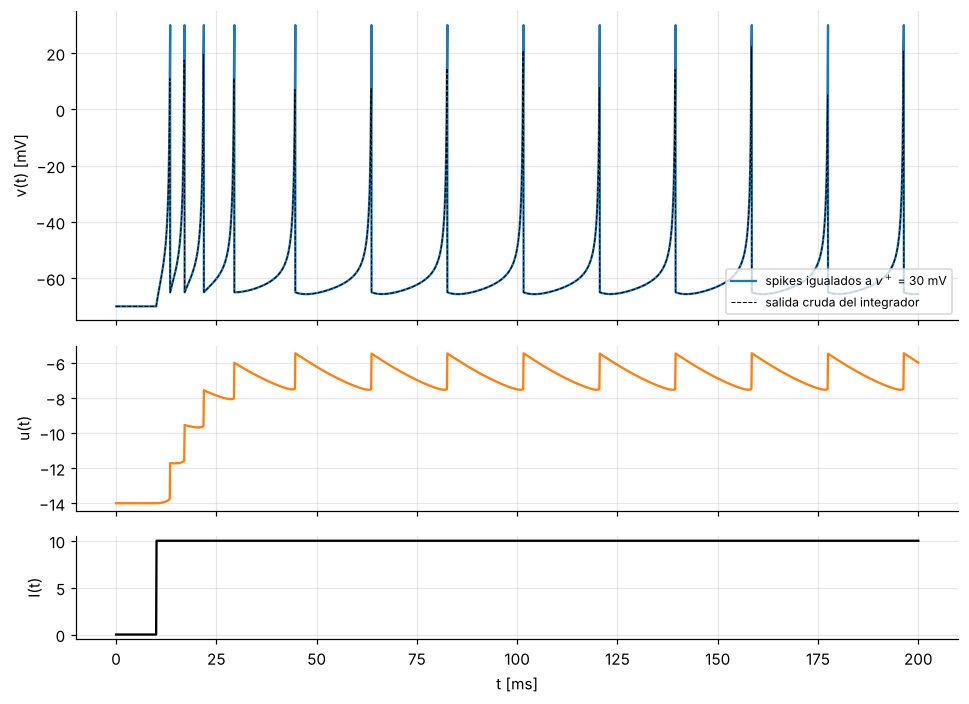

In [5]:
tt, vv = con_picos(t, w)
fig, ax = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.6, 1]})
ax[0].plot(tt, vv, color='tab:blue', label='spikes igualados a $v^+$ = 30 mV')
ax[0].plot(t, w[0], 'k--', lw=0.7, label='salida cruda del integrador')
ax[0].set_ylabel('v(t) [mV]'); ax[0].legend(loc='lower right', fontsize=8)
ax[1].plot(t, w[1], color='tab:orange'); ax[1].set_ylabel('u(t)')
ax[2].plot(t, [I_base(s) for s in t], 'k'); ax[2].set_ylabel('I(t)'); ax[2].set_xlabel('t [ms]')
plt.tight_layout(); plt.show()

### 2.3) Los últimos ocho paneles de la figura 2 del paper

| Caso | b | c | v⁻ | Δu | I |
|---|---|---|---|---|---|
| RS | 0.02 | 0.2 | −65 | 8 | I₁ |
| IB | 0.02 | 0.2 | −55 | 4 | I₁ |
| CH | 0.02 | 0.2 | −50 | 2 | I₁ |
| FS | 0.1 | 0.2 | −65 | 2 | I₁ |
| TC1 | 0.02 | 0.25 | −65 | 0.05 | I₂ |
| TC2 | 0.02 | 0.25 | −65 | 0.05 | I₃ |
| RZ | 0.1 | 0.26 | −65 | 2 | I₄ |
| LTS | 0.02 | 0.25 | −65 | 2 | I₁ |

**Condición inicial:** cada caso arranca en su reposo, $v(0)=v^*(c)$ y $u(0)=c\,v(0)$. Para $c=0.2$ eso da exactamente $-70$ (lo que pide la consigna); para $c=0.25$ da $-64.4$ y para $c=0.26$ da $-62.5$. Arrancar de $-70$ en TC, RZ y LTS produce spikes espurios antes del estímulo (ver el análisis extra 3).

In [6]:
I1 = escalon(25, 10.0)
I2 = escalon(150, 2.5)
I3 = escalon(100, 0.0, Iantes=-15.0)
def I4(t):
    if t < 10:   return 0.0
    if t < 100:  return 0.2
    if t < 101:  return 10.0
    return 0.2

CASOS = {  #  b     c     v-    du    I
    'RS':  (0.02, 0.20, -65, 8.00, I1),
    'IB':  (0.02, 0.20, -55, 4.00, I1),
    'CH':  (0.02, 0.20, -50, 2.00, I1),
    'FS':  (0.10, 0.20, -65, 2.00, I1),
    'TC1': (0.02, 0.25, -65, 0.05, I2),
    'TC2': (0.02, 0.25, -65, 0.05, I3),
    'RZ':  (0.10, 0.26, -65, 2.00, I4),
    'LTS': (0.02, 0.25, -65, 2.00, I1),
}
NOMBRES = {'RS': 'regular spiking (RS)', 'IB': 'intrinsically bursting (IB)', 'CH': 'chattering (CH)',
           'FS': 'fast spiking (FS)', 'TC1': 'thalamo-cortical (TC), despolarizado',
           'TC2': 'thalamo-cortical (TC), rebote', 'RZ': 'resonator (RZ)', 'LTS': 'low-threshold spiking (LTS)'}

def p_caso(nombre):
    b, c, vm, du, I = CASOS[nombre]
    return parametros(b=b, c=c, v_menos=vm, du=du, I=I)

def simular(p, v0=None, T=200.0, h=0.1, metodo=rk4):
    c = p[6]
    if v0 is None:
        v0 = reposo(c)
    return integrador_ode(metodo, izhikevich, np.array([v0, c*v0]), 0.0, T, int(round(T/h)), p, reseteo)

RS   v(0)= -70.0  spikes= 5  t=[ 28.5  45.9  91.  135.9 180.8]
IB   v(0)= -70.0  spikes= 8  t=[ 28.5  30.7  34.2  71.8 103.1 134.4 165.7 197. ]
CH   v(0)= -70.0  spikes=18  t=[28.5 29.9 31.4 33.1 35.  37.2 40.  46.3]
FS   v(0)= -70.0  spikes=24  t=[28.5 32.5 38.1 45.1 52.5 60.1 67.6 75. ]
TC1  v(0)= -64.4  spikes= 5  t=[155.8 162.6 170.4 179.4 189.8]
TC2  v(0)= -64.4  spikes= 4  t=[107.4 113.4 120.9 131.7]


RZ   v(0)= -62.5  spikes= 3  t=[103.  144.5 186.9]
LTS  v(0)= -64.4  spikes=16  t=[27.5 30.5 34.1 38.7 45.3 55.7 69.  82.5]


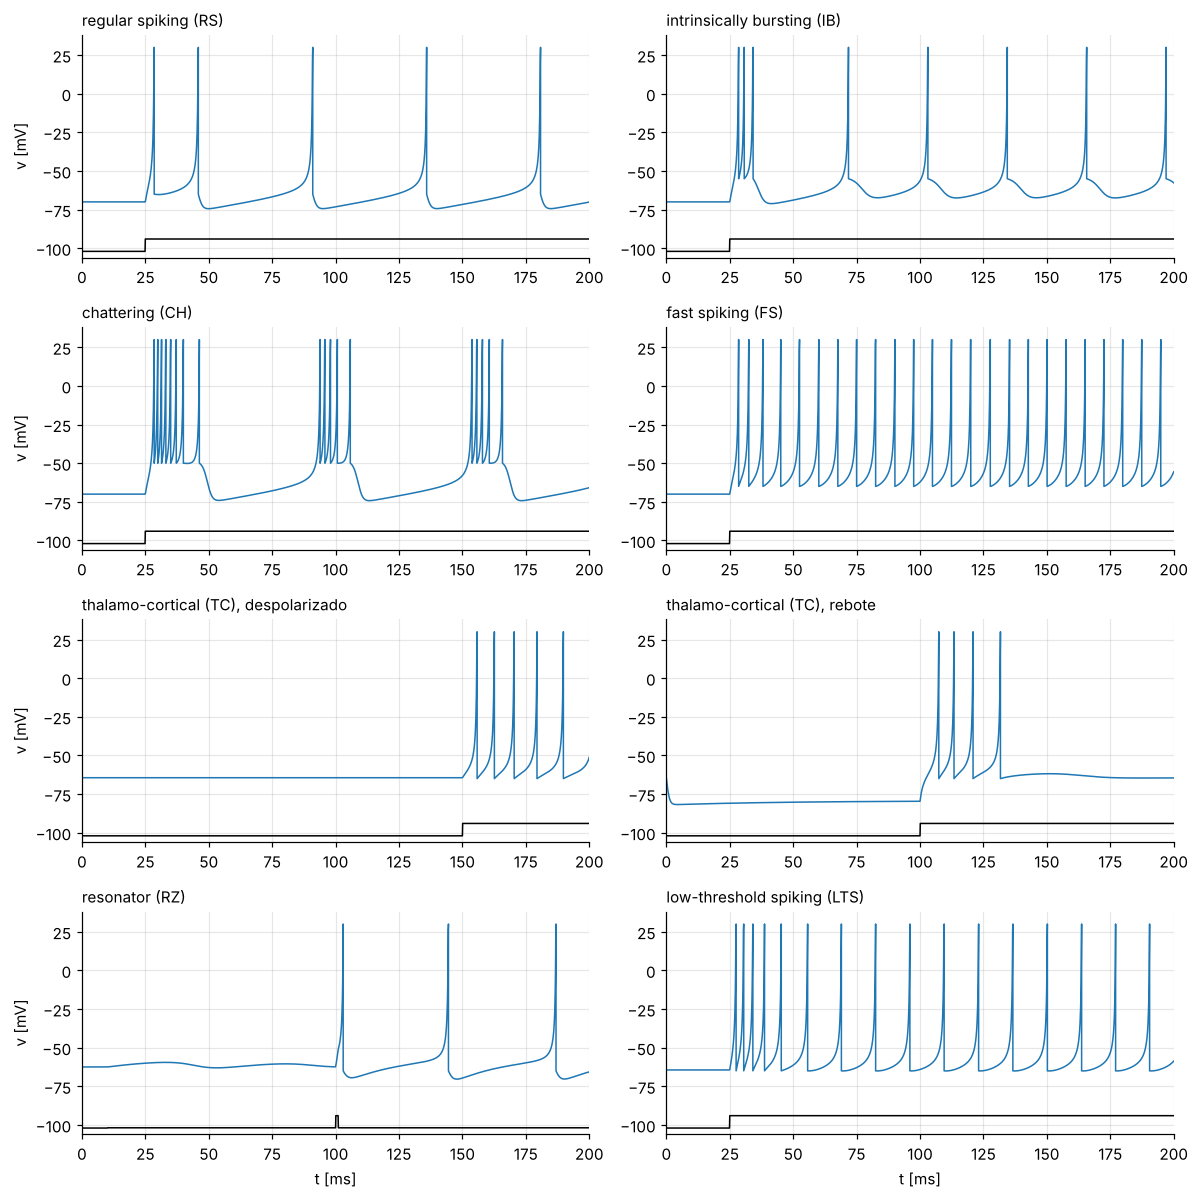

In [7]:
fig, axs = plt.subplots(4, 2, figsize=(11, 11))
for ax, nombre in zip(axs.flatten(), CASOS):
    pc = p_caso(nombre)
    t, w = simular(pc)
    tt, vv = con_picos(t, w)
    Iv = np.array([pc[8](s) for s in t])
    lo = min(vv.min(), -90)
    ax.plot(tt, vv, color='tab:blue', lw=1)
    ax.plot(t, lo - 12 + 8*(Iv - Iv.min())/max(np.ptp(Iv), 1e-9), 'k', lw=1)   # corriente (escala arbitraria)
    ax.set_title(NOMBRES[nombre], loc='left', fontsize=10)
    ax.set_ylim(lo - 16, 38); ax.set_xlim(0, 200)
    ts = t[indices_disparo(w)]
    print(f'{nombre:4s} v(0)={reposo(pc[6]):6.1f}  spikes={len(ts):2d}  t={np.round(ts[:8], 1)}')
for a in axs[-1]: a.set_xlabel('t [ms]')
for a in axs[:, 0]: a.set_ylabel('v [mV]')
plt.tight_layout(); plt.show()

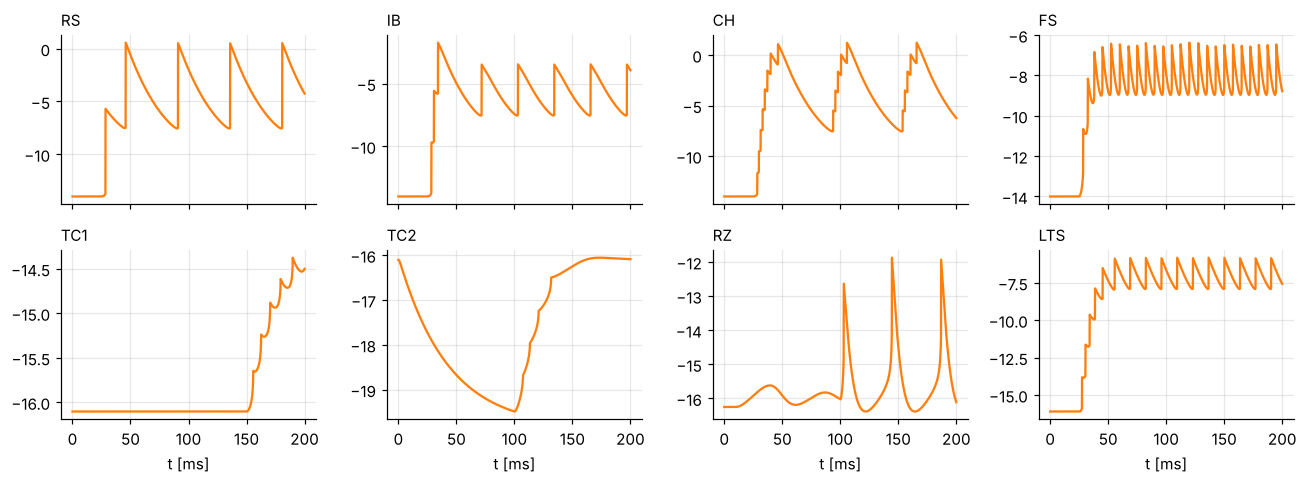

In [8]:
# Variable de recuperación u(t) en los ocho casos
fig, axs = plt.subplots(2, 4, figsize=(12, 4.5), sharex=True)
for ax, nombre in zip(axs.flatten(), CASOS):
    t, w = simular(p_caso(nombre))
    ax.plot(t, w[1], color='tab:orange'); ax.set_title(nombre, loc='left', fontsize=10)
for a in axs[-1]: a.set_xlabel('t [ms]')
plt.tight_layout(); plt.show()

## Análisis extra (para la discusión)

### 1) Bifurcaciones del reposo
Puntos fijos: $u^*=c\,v^*$ y $g_2 v^{*2} + (g_1-c)v^* + g_0 + I = 0$.
Saddle-node en $I_{SN}=(g_1-c)^2/(4g_2)-g_0$; Hopf cuando $\mathrm{tr}\,J = 2g_2v^*+g_1-b=0$ con $\det J>0$ (ocurre antes si $c>b$).

In [9]:
def bifurcaciones(b, c, g2=0.04, g1=5.0, g0=140.0):
    I_sn = (g1 - c)**2/(4*g2) - g0
    vH = (b - g1)/(2*g2)
    I_h = -(g2*vH**2 + (g1 - c)*vH + g0)
    hopf = I_h if (c > b and b*(c - (2*g2*vH + g1)) > 0) else None
    return I_sn, hopf

for nombre in ['RS', 'FS', 'LTS', 'RZ']:
    b, c = CASOS[nombre][:2]
    I_sn, I_h = bifurcaciones(b, c)
    print(f'{nombre:4s}  v*(I=0) = {reposo(c):6.2f} mV   I_Hopf = {I_h:5.2f}   I_SN = {I_sn:5.2f}')

RS    v*(I=0) = -70.00 mV   I_Hopf =  3.80   I_SN =  4.00
FS    v*(I=0) = -70.00 mV   I_Hopf =  3.94   I_SN =  4.00
LTS   v*(I=0) = -64.41 mV   I_Hopf =  0.69   I_SN =  1.02
RZ    v*(I=0) = -62.50 mV   I_Hopf =  0.26   I_SN =  0.42


### 2) Plano de fase (RS y CH) con nulclinas

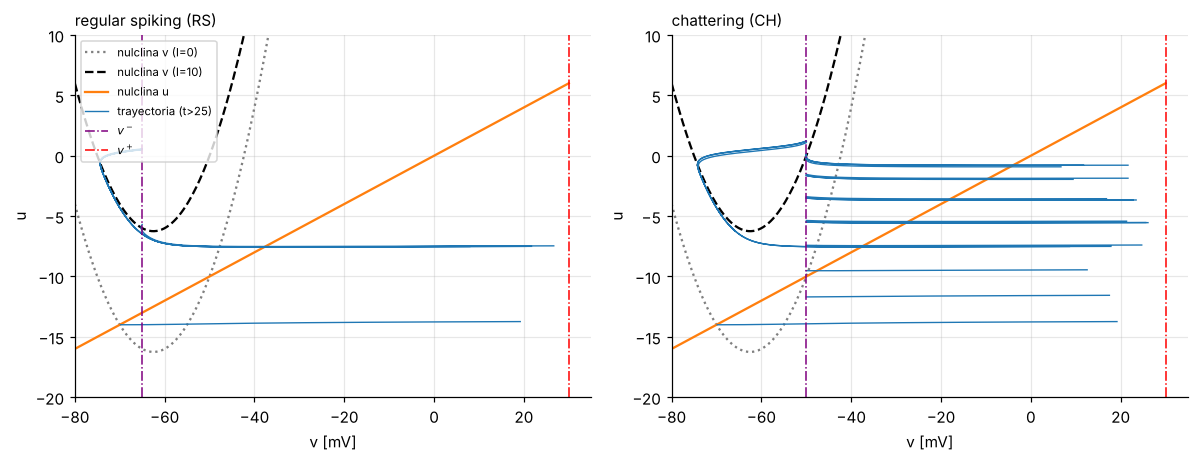

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, nombre in zip(axs, ['RS', 'CH']):
    pc = p_caso(nombre); c, vm = pc[6], pc[3]
    t, w = simular(pc)
    j = indices_disparo(w)
    v_, u_, t_ = np.insert(w[0], j, np.nan), np.insert(w[1], j, np.nan), np.insert(t, j, t[j])
    m = t_ >= 25
    V = np.linspace(-80, 30, 400)
    ax.plot(V, 0.04*V**2 + 5*V + 140, ':', color='gray', label='nulclina v (I=0)')
    ax.plot(V, 0.04*V**2 + 5*V + 140 + 10, 'k--', label='nulclina v (I=10)')
    ax.plot(V, c*V, color='tab:orange', label='nulclina u')
    ax.plot(v_[m], u_[m], color='tab:blue', lw=0.9, label='trayectoria (t>25)')
    ax.axvline(vm, color='purple', ls='-.', lw=1, label='$v^-$')
    ax.axvline(30, color='red', ls='-.', lw=1, label='$v^+$')
    ax.set_xlim(-80, 35); ax.set_ylim(-20, 10); ax.set_xlabel('v [mV]'); ax.set_ylabel('u')
    ax.set_title(NOMBRES[nombre], loc='left', fontsize=10)
axs[0].legend(fontsize=7.5, loc='upper left')
plt.tight_layout(); plt.show()

### 3) Curva f–I (frecuencia estacionaria vs corriente constante)

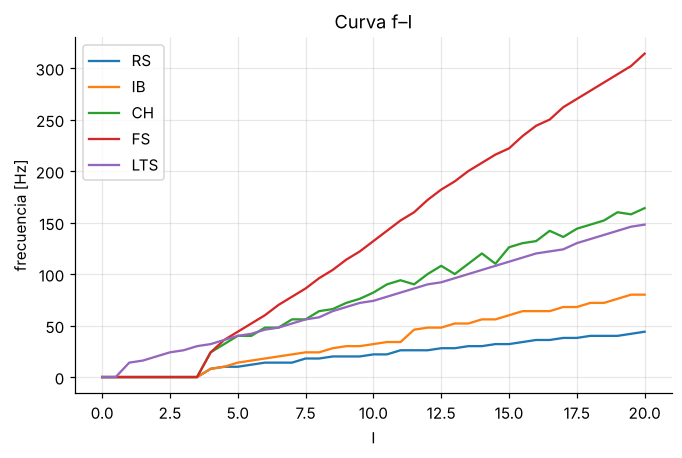

In [11]:
Is = np.linspace(0, 20, 41)
plt.figure(figsize=(7, 4.2))
for nombre in ['RS', 'IB', 'CH', 'FS', 'LTS']:
    b, c, vm, du, _ = CASOS[nombre]
    fr = []
    for I0 in Is:
        pc = parametros(b=b, c=c, v_menos=vm, du=du, I=lambda t, I0=I0: I0)
        t, w = simular(pc, T=1000)
        ts = t[indices_disparo(w)]
        fr.append(1000*np.sum(ts > 500)/500)     # Hz, en t ∈ [500, 1000] ms
    plt.plot(Is, fr, label=nombre)
plt.xlabel('I'); plt.ylabel('frecuencia [Hz]'); plt.legend(); plt.title('Curva f–I')
plt.show()

### 4) Sensibilidad a la condición inicial: v(0) = −70 vs reposo

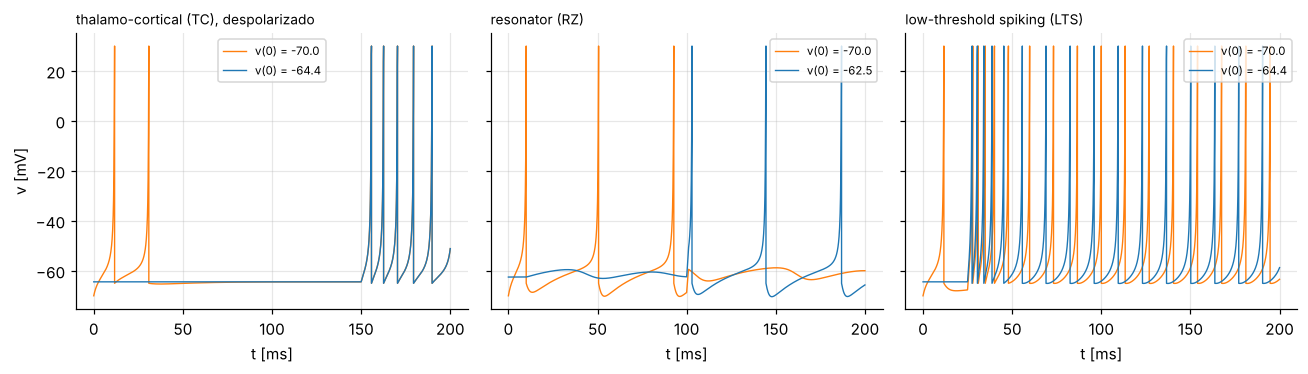

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, nombre in zip(axs, ['TC1', 'RZ', 'LTS']):
    pc = p_caso(nombre); c = pc[6]
    for v0, col in [(-70.0, 'tab:orange'), (reposo(c), 'tab:blue')]:
        t, w = simular(pc, v0=v0); tt, vv = con_picos(t, w)
        ax.plot(tt, vv, color=col, lw=0.9, label=f'v(0) = {v0:.1f}')
    ax.set_title(NOMBRES[nombre], loc='left', fontsize=9); ax.set_xlabel('t [ms]'); ax.legend(fontsize=7.5)
axs[0].set_ylabel('v [mV]')
plt.tight_layout(); plt.show()

### 5) Error numérico en los tiempos de disparo

Referencia: `scipy.integrate.solve_ivp` (DOP853, tolerancias $10^{-11}$) con detección exacta del evento $v=v^+$.
Se compara Euler, RK4 y RK4 con localización del cruce dentro del paso.

spikes de referencia [ms]: [ 28.4516  45.5561  90.4921 135.3045 180.1169]


       h      Euler        RK4   RK4+evento
  0.4000     7.0831     5.4831      0.78035
  0.2000     3.0831     1.4831      0.27738
  0.1000     1.7831     0.6831      0.09248
  0.0500     0.7331     0.2831      0.02278
  0.0250     0.3831     0.1331      0.00706
  0.0125     0.2081     0.0831      0.00276


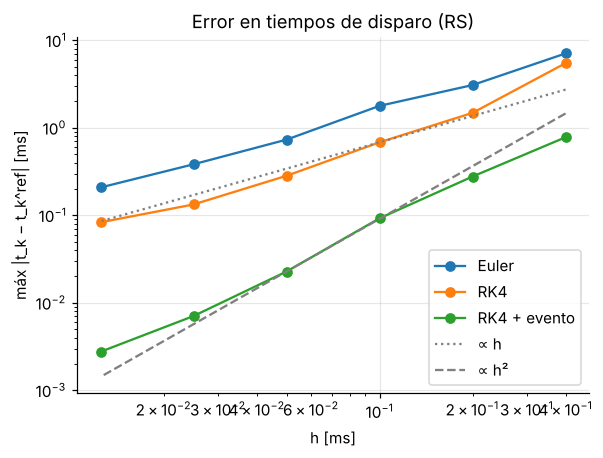

In [13]:
from scipy.integrate import solve_ivp

def spikes_referencia(p, T=200.0, cortes=(25.0,)):
    g2, g1, g0, vm, vp, b, c, du, I = p
    x = np.array([reposo(c), c*reposo(c)]); t0 = 0.0; out = []
    ev = lambda t, x: x[0] - vp; ev.terminal = True; ev.direction = 1
    while t0 < T:
        tf = min([s for s in cortes if s > t0] + [T])      # respeta la discontinuidad de I
        s = solve_ivp(lambda t, x: izhikevich(x, t, p), (t0, tf), x, events=ev,
                      rtol=1e-11, atol=1e-11, method='DOP853', max_step=0.05)
        if s.status == 1:
            ts = s.t_events[0][0]; out.append(ts)
            x = np.array([vm, s.y_events[0][0][1] + du]); t0 = ts
        else:
            x = s.y[:, -1]; t0 = tf
    return np.array(out)

def integrador_eventos(f, xa, a, b, k, p):
    """RK4 + localización del cruce v = v+ por interpolación lineal dentro del paso."""
    vp, vm, du = p[4], p[3], p[7]
    h = (b - a)/k
    t = a + h*np.arange(k+1)
    w = np.zeros((len(xa), k+1)); w[:, 0] = xa
    spikes = []
    for j in range(k):
        x = w[:, j]
        y = rk4(f, x, t[j], h, p)
        if y[0] >= vp:
            th = (vp - x[0])/(y[0] - x[0])          # fracción del paso donde cruza
            xs = rk4(f, x, t[j], th*h, p)
            ts = t[j] + th*h; spikes.append(ts)
            xs = np.array([vm, xs[1] + du])          # reseteo en el instante del cruce
            y = rk4(f, xs, ts, (1 - th)*h, p)        # completo el paso
        w[:, j+1] = y
    return t, w, np.array(spikes)

pc = p_caso('RS')
tref = spikes_referencia(pc)
print('spikes de referencia [ms]:', np.round(tref, 4))

hs = [0.4, 0.2, 0.1, 0.05, 0.025, 0.0125]
err = {'Euler': [], 'RK4': [], 'RK4 + evento': []}
for h in hs:
    k = int(round(200/h))
    for nombre_m, m in [('Euler', euler), ('RK4', rk4)]:
        t, w = simular(pc, h=h, metodo=m)
        ts = t[indices_disparo(w)]
        err[nombre_m].append(np.max(np.abs(ts - tref)) if len(ts) == len(tref) else np.nan)
    v0 = reposo(pc[6])
    _, _, ts = integrador_eventos(izhikevich, np.array([v0, pc[6]*v0]), 0, 200, k, pc)
    err['RK4 + evento'].append(np.max(np.abs(ts - tref)) if len(ts) == len(tref) else np.nan)

print(f"{'h':>8s} {'Euler':>10s} {'RK4':>10s} {'RK4+evento':>12s}")
for i, h in enumerate(hs):
    print(f"{h:8.4f} {err['Euler'][i]:10.4f} {err['RK4'][i]:10.4f} {err['RK4 + evento'][i]:12.5f}")

plt.figure(figsize=(6, 4.2))
for nombre_m, e in err.items():
    plt.loglog(hs, e, 'o-', label=nombre_m)
hh = np.array(hs)
plt.loglog(hh, err['RK4'][2]/hh[2]*hh, ':', color='gray', label='∝ h')
plt.loglog(hh, err['RK4 + evento'][3]/hh[3]**2*hh**2, '--', color='gray', label='∝ h²')
plt.xlabel('h [ms]'); plt.ylabel('máx |t_k − t_k^ref| [ms]'); plt.legend(); plt.title('Error en tiempos de disparo (RS)')
plt.show()

## Ejercicio 3) Red de neuronas de Izhikevich (opcional)

$n_e=800$ excitatorias y $n_i=200$ inhibitorias, todas conectadas con todas. Con Euler–Maruyama:

$$Y_{t+\tau} = Y_t + f(Y_t,t)\,\tau + g(Y_t,t)\sqrt{\tau}\,N,\qquad N\sim\mathcal N(0,1).$$

Nota: el TP y la guía escriben $v_i^- = -64 + 15r_i^2$; el paper y su código usan $-65 + 15 r_i^2$, que es lo que usamos.

### 3.1) Traducción literal del código MATLAB del paper

tasa media: 7.5 Hz


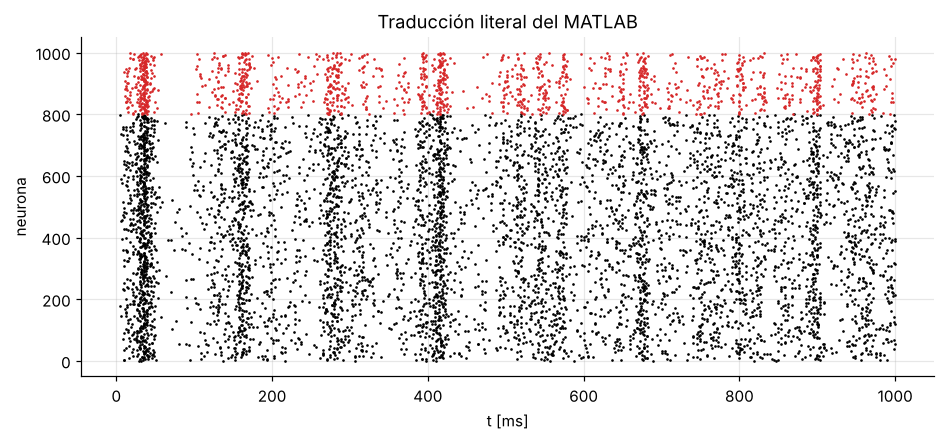

In [14]:
def red_matlab_literal(Ne=800, Ni=200, T=1000, seed=0):
    rng = np.random.default_rng(seed)
    re, ri = rng.random(Ne), rng.random(Ni)
    a = np.r_[0.02*np.ones(Ne), 0.02 + 0.08*ri]
    b = np.r_[0.2*np.ones(Ne), 0.25 - 0.05*ri]
    c = np.r_[-65 + 15*re**2, -65*np.ones(Ni)]
    d = np.r_[8 - 6*re**2, 2*np.ones(Ni)]
    S = np.hstack([0.5*rng.random((Ne+Ni, Ne)), -rng.random((Ne+Ni, Ni))])
    v = -65*np.ones(Ne+Ni); u = b*v
    firings = []
    for t in range(1, T+1):                                              # 1 ms por iteración
        I = np.r_[5*rng.standard_normal(Ne), 2*rng.standard_normal(Ni)]  # input talámico
        fired = np.flatnonzero(v >= 30)
        firings += [(t, i) for i in fired]
        v[fired] = c[fired]
        u[fired] = u[fired] + d[fired]
        I = I + S[:, fired].sum(axis=1)
        v = v + 0.5*(0.04*v**2 + 5*v + 140 - u + I)   # dos medios pasos de 0.5 ms
        v = v + 0.5*(0.04*v**2 + 5*v + 140 - u + I)   # "for numerical stability"
        u = u + a*(b*v - u)
    return np.array(firings)

fir = red_matlab_literal(seed=3)
print(f'tasa media: {len(fir)/1000/1.0:.1f} Hz')
plt.figure(figsize=(10, 4))
exc = fir[:, 1] < 800
plt.plot(fir[exc, 0], fir[exc, 1], 'k.', ms=1.5)
plt.plot(fir[~exc, 0], fir[~exc, 1], '.', color='tab:red', ms=1.5)
plt.xlabel('t [ms]'); plt.ylabel('neurona'); plt.title('Traducción literal del MATLAB'); plt.show()

### 3.2) Versión modularizada según la teoría (Euler–Maruyama), con Θ o z(v)

Cada componente de la teoría es una función: parámetros de la red, activación, drift $f$, difusión $g$, paso de Euler–Maruyama, reseteo e integrador.
Con Θ la entrada sináptica se divide por $\tau$ para que cada spike desplace $v_i$ en $a_{ij}$ mV, igual que en el paper (allí el pulso dura 1 ms).

In [15]:
def parametros_red(ne=800, ni=200, seed=None):
    rng = np.random.default_rng(seed)
    n = ne + ni
    re, ri = rng.random(ne), rng.random(ni)
    b       = np.concatenate([0.02*np.ones(ne), 0.02 + 0.08*ri])
    c       = np.concatenate([0.2*np.ones(ne),  0.25 - 0.05*ri])
    v_menos = np.concatenate([-65 + 15*re**2,   -65*np.ones(ni)])
    du      = np.concatenate([8 - 6*re**2,       2*np.ones(ni)])
    A = np.hstack([0.5*rng.random((n, ne)), -rng.random((n, ni))])   # a_ij
    w = np.concatenate([5*np.ones(ne), 2*np.ones(ni)])               # g_ii (ruido)
    return dict(ne=ne, ni=ni, n=n, b=b, c=c, v_menos=v_menos, du=du,
                A=A, w=w, g2=0.04, g1=5.0, g0=140.0, v_mas=30.0)

def theta(v, p):
    """Heaviside: 1 si la neurona alcanzó v+."""
    return (v >= p['v_mas']).astype(float)

def z(v, p):
    """Reemplazo de Θ: z(v) = (87+v)/450 - 0.0193 (v recortado en v+)."""
    return (87.0 + np.minimum(v, p['v_mas']))/450.0 - 0.0193

def drift(v, u, I_syn, p):
    fv = p['g2']*v**2 + p['g1']*v + p['g0'] - u + I_syn
    fu = p['b']*(p['c']*v - u)
    return fv, fu

def paso_euler_maruyama(v, u, I_syn, tau, p, rng):
    fv, fu = drift(v, u, I_syn, p)
    N = rng.standard_normal(p['n'])
    return v + fv*tau + p['w']*np.sqrt(tau)*N, u + fu*tau     # sólo V tiene ruido

def reseteo_red(v, u, p):
    disparo = v >= p['v_mas']
    v = np.where(disparo, p['v_menos'], v)
    u = np.where(disparo, u + p['du'], u)
    return v, u, disparo

def simular_red(p, T=1000.0, tau=0.5, activacion=theta, seed=None, registrar=0):
    rng = np.random.default_rng(seed)
    k = int(round(T/tau))
    v = -65.0*np.ones(p['n']); u = p['c']*v
    t_spk, i_spk = [], []
    t_reg = np.arange(k+1)*tau
    v_reg = np.zeros(k+1); v_reg[0] = v[registrar]
    for j in range(k):
        t = j*tau
        I_syn = p['A'] @ activacion(v, p)          # con v antes del reseteo
        if activacion is theta:
            I_syn = I_syn/tau
        v, u, disparo = reseteo_red(v, u, p)
        idx = np.flatnonzero(disparo)
        t_spk.append(np.full(idx.size, t)); i_spk.append(idx)
        if disparo[registrar]:
            v_reg[j] = p['v_mas']
        v, u = paso_euler_maruyama(v, u, I_syn, tau, p, rng)
        v_reg[j+1] = min(v[registrar], p['v_mas'])
    return np.concatenate(t_spk), np.concatenate(i_spk), t_reg, v_reg

def graficar_fig3(t_spk, i_spk, t, v1, p, titulo=''):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    exc = i_spk < p['ne']
    ax1.plot(t_spk[exc], i_spk[exc], 'k.', ms=1.2)
    ax1.plot(t_spk[~exc], i_spk[~exc], '.', color='tab:red', ms=1.2)
    ax1.axhline(p['ne'], color='gray', lw=0.8)
    ax1.set_ylabel('neurona'); ax1.set_ylim(0, p['n']); ax1.set_title(titulo); ax1.grid(False)
    ax2.plot(t, v1, color='tab:blue', lw=0.7)
    ax2.set_xlabel('t [ms]'); ax2.set_ylabel('$v_1(t)$ [mV]'); ax2.set_xlim(0, t[-1])
    plt.tight_layout(); plt.show()

Θ:    tasa media = 9.1 Hz


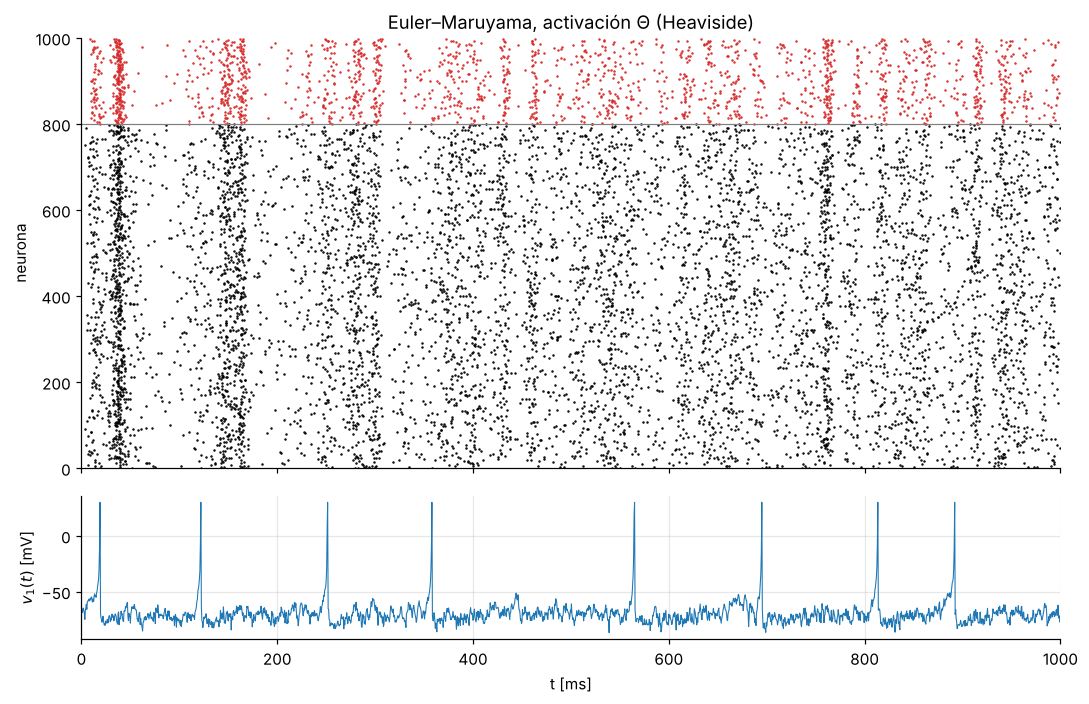

In [16]:
T = 1000.0
p_red = parametros_red(seed=1)

ts_t, is_t, tr, v1_t = simular_red(p_red, T=T, tau=0.5, activacion=theta, seed=2)
print(f'Θ:    tasa media = {ts_t.size/(p_red["n"]*T*1e-3):.1f} Hz')
graficar_fig3(ts_t, is_t, tr, v1_t, p_red, 'Euler–Maruyama, activación Θ (Heaviside)')

z(v): tasa media = 9.7 Hz


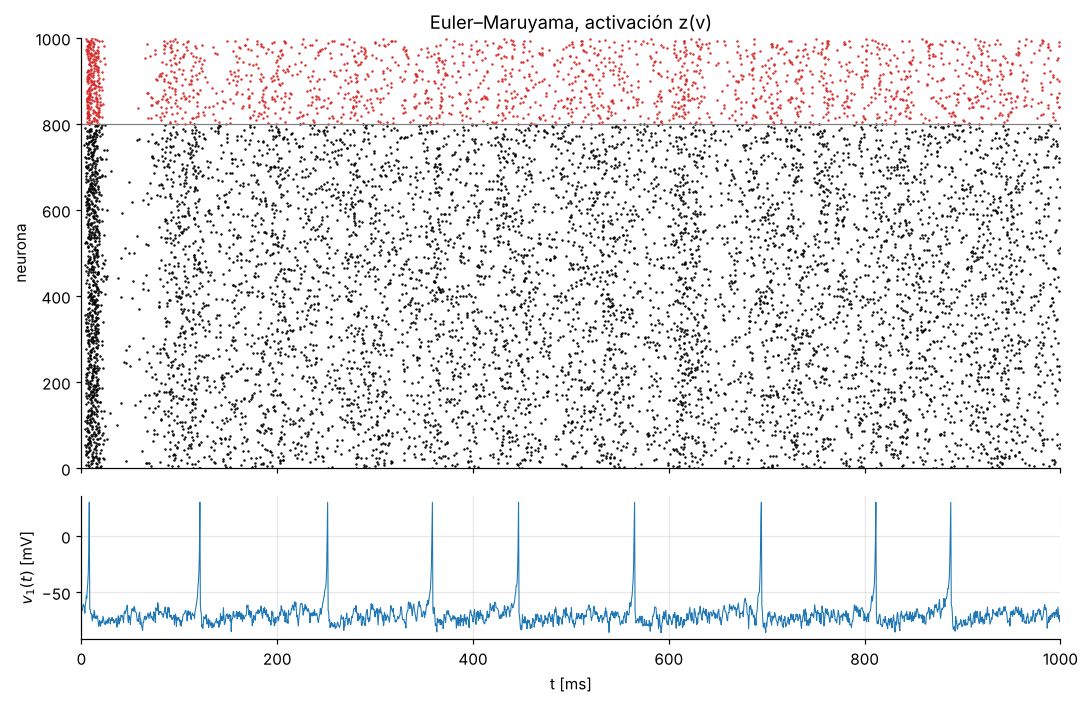

In [17]:
ts_z, is_z, tr_z, v1_z = simular_red(p_red, T=T, tau=0.5, activacion=z, seed=2)
print(f'z(v): tasa media = {ts_z.size/(p_red["n"]*T*1e-3):.1f} Hz')
graficar_fig3(ts_z, is_z, tr_z, v1_z, p_red, 'Euler–Maruyama, activación z(v)')

### 3.3) Actividad poblacional y espectro (ritmos α ≈ 10 Hz y γ ≈ 40 Hz)

Θ     pico espectral = 35.2 Hz   CV de la tasa = 0.69


z(v)  pico espectral = 11.7 Hz   CV de la tasa = 0.41


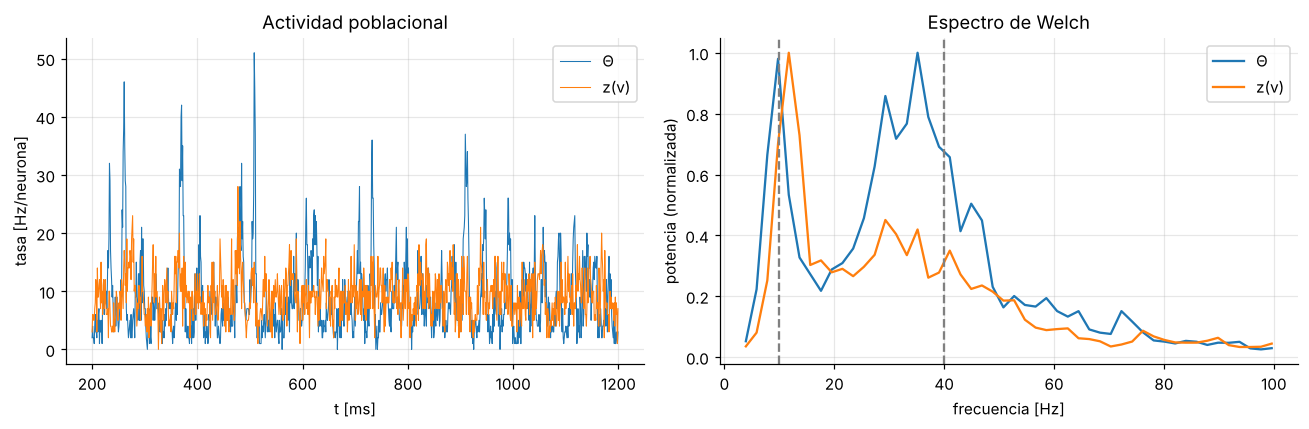

In [18]:
from scipy.signal import welch

def tasa_poblacional(t_spk, T, n, bin_ms=1.0):
    bins = np.arange(0, T + bin_ms, bin_ms)
    cuentas, _ = np.histogram(t_spk, bins)
    return bins[:-1], cuentas/(n*bin_ms*1e-3)       # Hz por neurona

TL = 5000.0
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for act, nombre in [(theta, 'Θ'), (z, 'z(v)')]:
    ts_, *_ = simular_red(p_red, T=TL, tau=0.5, activacion=act, seed=5)
    tb, tasa = tasa_poblacional(ts_, TL, p_red['n'])
    m = (tb >= 200) & (tb < 1200)
    axs[0].plot(tb[m], tasa[m], lw=0.7, label=nombre)
    x = tasa[tb >= 200]
    f, P = welch(x - x.mean(), fs=1000, nperseg=512)
    sel = (f > 2) & (f < 100)
    axs[1].plot(f[sel], P[sel]/P[sel].max(), label=nombre)
    print(f'{nombre:5s} pico espectral = {f[sel][np.argmax(P[sel])]:.1f} Hz   CV de la tasa = {x.std()/x.mean():.2f}')
for f0 in (10, 40): axs[1].axvline(f0, ls='--', color='gray')
axs[0].set(xlabel='t [ms]', ylabel='tasa [Hz/neurona]', title='Actividad poblacional')
axs[1].set(xlabel='frecuencia [Hz]', ylabel='potencia (normalizada)', title='Espectro de Welch')
axs[0].legend(); axs[1].legend(); plt.tight_layout(); plt.show()